In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
import warnings
warnings.filterwarnings('ignore')
%config InlineBackend.figure_format = 'svg'

# 1. Load the dataset
df = pd.read_csv('Train.csv')
print(df.head())

# 2. Clean column names (lowercase and replace spaces/dots with underscores)
df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('.', '_')

# 3. Rename target variable for clarity (1 = Late, 0 = On Time)
df = df.rename(columns={'reached_on_time_y_n': 'target'}) 

# Drop ID as it is not a predictive feature
df.drop('id', axis=1, inplace=True)

# 4. Split data: 60% train, 20% validation, 20% test
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

# Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Isolate target variables
y_train = df_train.target.values
y_val = df_val.target.values
y_test = df_test.target.values

del df_train['target']
del df_val['target']
del df_test['target']

print("Data split complete. Training set shape:", df_train.shape)

   ID Warehouse_block Mode_of_Shipment  Customer_care_calls  Customer_rating  \
0   1               D           Flight                    4                2   
1   2               F           Flight                    4                5   
2   3               A           Flight                    2                2   
3   4               B           Flight                    3                3   
4   5               C           Flight                    2                2   

   Cost_of_the_Product  Prior_purchases Product_importance Gender  \
0                  177                3                low      F   
1                  216                2                low      M   
2                  183                4                low      M   
3                  176                4             medium      M   
4                  184                3             medium      F   

   Discount_offered  Weight_in_gms  Reached.on.Time_Y.N  
0                44           1233            

Missing values in dataset:
 warehouse_block        0
mode_of_shipment       0
customer_care_calls    0
customer_rating        0
cost_of_the_product    0
prior_purchases        0
product_importance     0
gender                 0
discount_offered       0
weight_in_gms          0
target                 0
dtype: int64

Target Distribution (1 = Late, 0 = On Time):


target
1    0.597568
0    0.402432
Name: proportion, dtype: float64


Mutual Information (Categorical features):
 product_importance    0.000649
warehouse_block       0.000182
mode_of_shipment      0.000045
gender                0.000003
dtype: float64


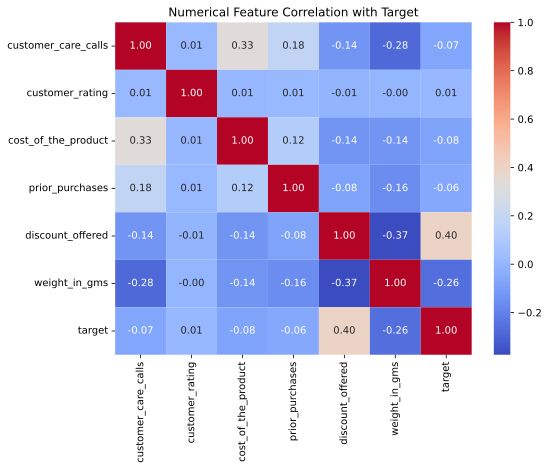

In [2]:
# Check for missing values
print("Missing values in dataset:\n", df_full_train.isnull().sum())

# Target variable distribution
print("\nTarget Distribution (1 = Late, 0 = On Time):")
display(df_full_train.target.value_counts(normalize=True))

# Define categorical and numerical features
numerical = ['customer_care_calls', 'customer_rating', 'cost_of_the_product', 'prior_purchases', 'discount_offered', 'weight_in_gms']
categorical = ['warehouse_block', 'mode_of_shipment', 'product_importance', 'gender']

# Feature importance: Mutual Information for categorical features
from sklearn.metrics import mutual_info_score
def mutual_info_target(series):
    return mutual_info_score(series, df_full_train.target)
    
mi_scores = df_full_train[categorical].apply(mutual_info_target).sort_values(ascending=False)
print("\nMutual Information (Categorical features):\n", mi_scores)

# Feature importance: Correlation matrix for numerical features
correlation_matrix = df_full_train[numerical + ['target']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Numerical Feature Correlation with Target')
plt.savefig('correlation_heatmap.svg', format='svg', bbox_inches='tight')
plt.show()

In [3]:
from sklearn.linear_model import LogisticRegression

# One-hot encode the categorical variables using DictVectorizer
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Train Baseline Model: Logistic Regression
lr = LogisticRegression(solver='liblinear', random_state=42)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict_proba(X_val)[:, 1]
print("Logistic Regression AUC:", roc_auc_score(y_val, y_pred_lr))

Logistic Regression AUC: 0.6944095549990368


In [4]:
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb

# Train Model 2: Decision Tree
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict_proba(X_val)[:, 1]
print("Decision Tree AUC:", roc_auc_score(y_val, y_pred_dt))

# Train Model 3: XGBoost (with parameter tuning)
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=dv.get_feature_names_out().tolist())
dval = xgb.DMatrix(X_val, label=y_val, feature_names=dv.get_feature_names_out().tolist())

xgb_params = {
    'eta': 0.1, 
    'max_depth': 4,
    'min_child_weight': 1,
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'nthread': 8,
    'seed': 42
}

model_xgb = xgb.train(xgb_params, dtrain, num_boost_round=100)
y_pred_xgb = model_xgb.predict(dval)
print("XGBoost AUC:", roc_auc_score(y_val, y_pred_xgb))

Decision Tree AUC: 0.7203600248292985
XGBoost AUC: 0.7251448019007256
